# Model Training 3 - Multilayer Perceptron (MLP)
Using tensorflow and keras

## 1. Feature Selection

In [44]:
# imports
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [45]:
# train and test data
train_df = pd.read_csv("../Data/TrainPreprocessed.csv")
test_df = pd.read_csv("../Data/TestPreprocessed.csv")

# drop norad id 
train_df = train_df.drop(columns=["NORAD_CAT_ID"])
test_df = test_df.drop(columns=["NORAD_CAT_ID"])

In [46]:
# function to plot model evaluation
sns.set_theme(style="whitegrid")

def plot_model_evaluation(y_true, y_pred, title="Model Evaluation"):
    """
    Plot residual, prediction, and ground truth diagnostics for regression models.
    
    Parameters:
        y_true (array-like): Ground truth values
        y_pred (array-like): Model predictions
        title (str): Title of the overall plot
    """
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()
    residuals = y_pred - y_true

    # Create figure layout
    fig, axs = plt.subplots(3, 2, figsize=(14, 14))
    fig.suptitle(title, fontsize=16)

    # 1. Residual Histogram
    sns.histplot(residuals, bins=60, ax=axs[0, 0], color="C0")
    axs[0, 0].set_title("Residual Histogram")
    axs[0, 0].set_xlabel("Residual")
    axs[0, 0].set_ylabel("Density")

    # 2. Ground Truth Histogram
    sns.histplot(y_true, bins=60, ax=axs[0, 1], color="C0")
    axs[0, 1].set_title("Ground Truth Histogram")
    axs[0, 1].set_xlabel("Ground truth")
    axs[0, 1].set_ylabel("Density")

    # 3. Prediction Histogram
    sns.histplot(y_pred, bins=60, ax=axs[1, 0], color="C0")
    axs[1, 0].set_title("Prediction Histogram")
    axs[1, 0].set_xlabel("Prediction")
    axs[1, 0].set_ylabel("Density")

    # 4. Ground Truth vs Predictions (binned)
    df_gt_pred = pd.DataFrame({"ground_truth": y_true, "prediction": y_pred})
    df_gt_pred["gt_bin"] = pd.cut(df_gt_pred["ground_truth"], bins=30)
    binned_gt = df_gt_pred.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["prediction"], label="Prediction", color="darkorange")
    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["ground_truth"], linestyle="--", color="C0", label="Ideal")
    axs[1, 1].set_title("Ground Truth vs Predictions (Binned)")
    axs[1, 1].set_xlabel("Ground Truth")
    axs[1, 1].set_ylabel("Prediction")
    axs[1, 1].legend()

    # 5. Predictions vs Residual (binned)
    df_pred_res = pd.DataFrame({"prediction": y_pred, "residual": residuals})
    df_pred_res["pred_bin"] = pd.cut(df_pred_res["prediction"], bins=30)
    binned_pred = df_pred_res.groupby("pred_bin", observed=False).mean(numeric_only=True)

    axs[2, 0].plot(binned_pred["prediction"], binned_pred["residual"], color="darkorange")
    axs[2, 0].axhline(0, linestyle="--", color="C0")
    axs[2, 0].set_title("Predictions vs Residual (Binned)")
    axs[2, 0].set_xlabel("Prediction")
    axs[2, 0].set_ylabel("Residual")

    # 6. Ground Truth vs Residual (binned)
    df_gt_res = pd.DataFrame({"ground_truth": y_true, "residual": residuals})
    df_gt_res["gt_bin"] = pd.cut(df_gt_res["ground_truth"], bins=30)
    binned_gt_res = df_gt_res.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[2, 1].plot(binned_gt_res["ground_truth"], binned_gt_res["residual"], color="darkorange")
    axs[2, 1].axhline(0, linestyle="--", color="C0")
    axs[2, 1].set_title("Ground Truth vs Residual (Binned)")
    axs[2, 1].set_xlabel("Ground Truth")
    axs[2, 1].set_ylabel("Residual")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


In [47]:
# function for analyzing RMSE for different remaining lifetimes
def split_rmse_analysis(y_true, y_pred, threshold=2000):
    """
    Compute RMSE separately for low and high remaining lifetimes.
    
    Parameters:
    - y_true: true values (array-like or pandas Series)
    - y_pred: predicted values (array-like or pandas Series)
    - threshold: cutoff value for binning (default is 2000)
    
    Returns:
    - Dictionary with RMSE for below and above the threshold
    """
    # Ensure arrays
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()

    # Create masks
    mask_low = y_true <= threshold
    mask_high = y_true > threshold

    # Compute RMSEs
    rmse_low = np.sqrt(mean_squared_error(y_true[mask_low], y_pred[mask_low]))
    rmse_high = np.sqrt(mean_squared_error(y_true[mask_high], y_pred[mask_high]))
    
    return {"RMSE_low": rmse_low, "RMSE_high": rmse_high}

In [48]:
# Function to compute permutation importance for a model
def compute_permutation_importance(model, X, y, model_name):
    # Calculate the baseline RMSE 
    baseline_rmse = np.sqrt(mean_squared_error(y, model.predict(X)))
    print(f"{model_name} - Baseline RMSE: {baseline_rmse:.2f}")
    
    importances = {}
    X_copy = X.copy() # Create a copy of the input features to avoid modifying the original data
    
    for col in X.columns:
        # Shuffle the values of the current feature -> simulates a scenario where the feature is not informative
        X_shuffled = X_copy.copy()
        X_shuffled[col] = np.random.permutation(X_shuffled[col])
        
        # Predict and measure new rsme
        y_pred_shuffled = model.predict(X_shuffled)
        rmse = np.sqrt(mean_squared_error(y, y_pred_shuffled))
        
        # Compute the importance as the difference between the shuffled RMSE and the baseline RMSE
        importances[col] = rmse - baseline_rmse

    # Convert the importances dictionary to a DataFrame, sort by importance, and return
    return pd.DataFrame.from_dict(importances, orient='index', columns=['Importance']).sort_values(by='Importance', ascending=False)

### Model 1.1 - using all default features

In [49]:
# define features and labels fpr this model
X_train1_1 = train_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME", "DAYS_SINCE_LAUNCH"])
y_train1_1 = train_df["LIFETIME"]

X_test1_1 = test_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME", "DAYS_SINCE_LAUNCH"])
y_test1_1 = test_df["LIFETIME"]

In [50]:
# define model architecture
model1_1 = keras.Sequential([
    layers.Input(shape=(X_train1_1.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="relu")  # ensure output is non-negative
])

In [51]:
# compile model
model1_1.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[keras.metrics.RootMeanSquaredError()]
)

In [52]:
# train model
early_stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model1_1.fit(
    X_train1_1, y_train1_1,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 29870318.0000 - root_mean_squared_error: 5452.8960 - val_loss: 11221918.0000 - val_root_mean_squared_error: 3349.9131
Epoch 2/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 7695750.0000 - root_mean_squared_error: 2769.8677 - val_loss: 6673351.0000 - val_root_mean_squared_error: 2583.2830
Epoch 3/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 730us/step - loss: 3988551.0000 - root_mean_squared_error: 1994.0315 - val_loss: 4495626.0000 - val_root_mean_squared_error: 2120.2891
Epoch 4/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 732us/step - loss: 2387578.0000 - root_mean_squared_error: 1539.7290 - val_loss: 3333286.5000 - val_root_mean_squared_error: 1825.7290
Epoch 5/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 775us/step - loss: 1385487.5000 - root_mean_squared_error: 1175.5417 - val_loss: 2507694.2500 - val_root_mean_squared_error: 1583.5701
Epoch 6/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 683us/step - loss: 1081593.6250 - root_mean_squared_error: 1039

In [53]:
# evaluate model
loss, rmse = model1_1.evaluate(X_test1_1, y_test1_1)
print("Test RMSE:", rmse)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 843317.6250 - root_mean_squared_error: 915.6898
Test RMSE: 918.89208984375


153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 730us/step


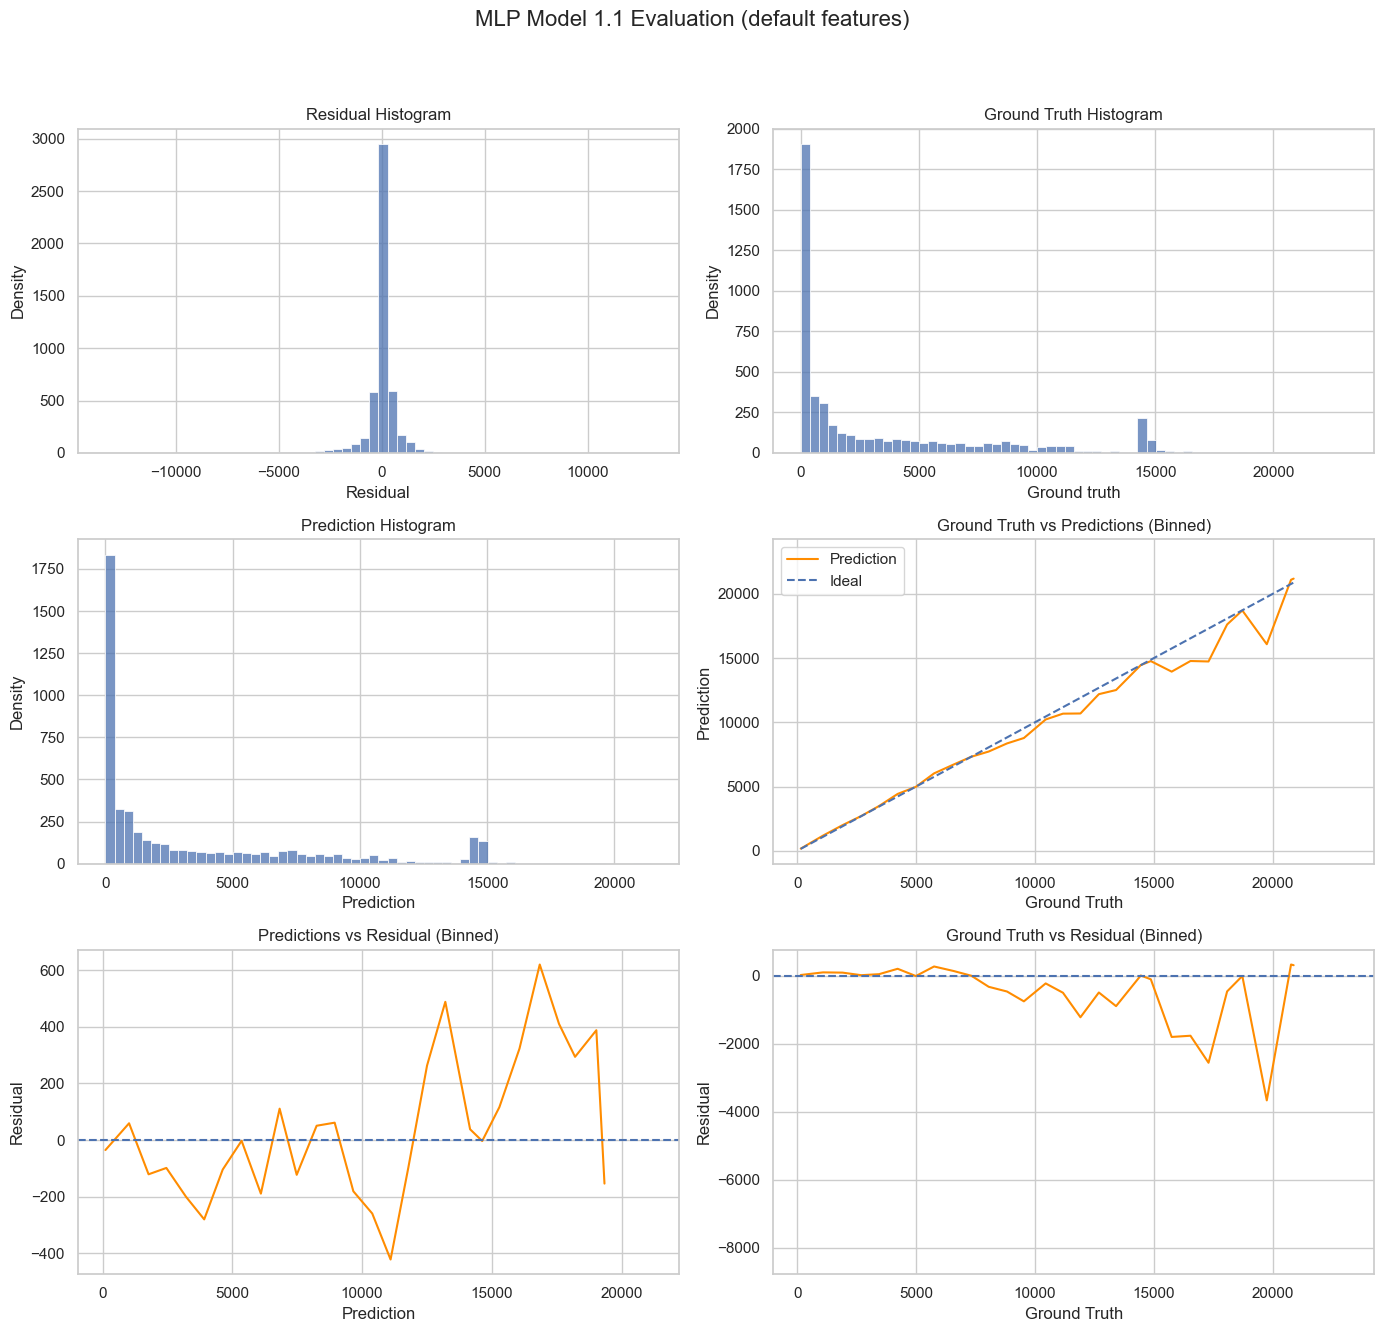

In [54]:
# plot model evaluation
y_pred1_1 = model1_1.predict(X_test1_1)
plot_model_evaluation(y_test1_1, y_pred1_1, title="MLP Model 1.1 Evaluation (default features)")

In [55]:
# save model
model1_1.save("../Models/MLP1_1.keras")

### Model 1.2 - Including engineered feature 'DAYS_SINCE_LAUNCH'

In [56]:
# define features and labels fpr this model
X_train1_2 = train_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_train1_2 = train_df["LIFETIME"]

X_test1_2 = test_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_test1_2 = test_df["LIFETIME"]

In [57]:
# define model architecture
model1_2 = keras.Sequential([
    layers.Input(shape=(X_train1_2.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="relu")  # ensure output is non-negative
])

In [58]:
# compile model
model1_2.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[keras.metrics.RootMeanSquaredError()]
)

In [59]:
# train model
early_stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model1_2.fit(
    X_train1_2, y_train1_2,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 1s 969us/step - loss: 30042846.0000 - root_mean_squared_error: 5454.5703 - val_loss: 6460912.5000 - val_root_mean_squared_error: 2541.8325
Epoch 2/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 683us/step - loss: 3141384.0000 - root_mean_squared_error: 1767.0210 - val_loss: 3391766.5000 - val_root_mean_squared_error: 1841.6749
Epoch 3/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 637us/step - loss: 1284011.7500 - root_mean_squared_error: 1131.8406 - val_loss: 2689750.7500 - val_root_mean_squared_error: 1640.0460
Epoch 4/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 643us/step - loss: 1295705.3750 - root_mean_squared_error: 1137.0010 - val_loss: 2315207.0000 - val_root_mean_squared_error: 1521.5804
Epoch 5/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 727us/step - loss: 1237150.3750 - root_mean_squared_error: 1108.8530 - val_loss: 2049505.7500 - val_root_mean_squared_error: 1431.6095
Epoch 6/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 664us/step - loss: 1028272.3750 - root_mean_squared_error: 1

In [60]:
# evaluate model
loss, rmse = model1_2.evaluate(X_test1_2, y_test1_2)
print("Test RMSE:", rmse)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 563us/step - loss: 5537610.5000 - root_mean_squared_error: 2012.7908
Test RMSE: 3022.5615234375


153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 400us/step


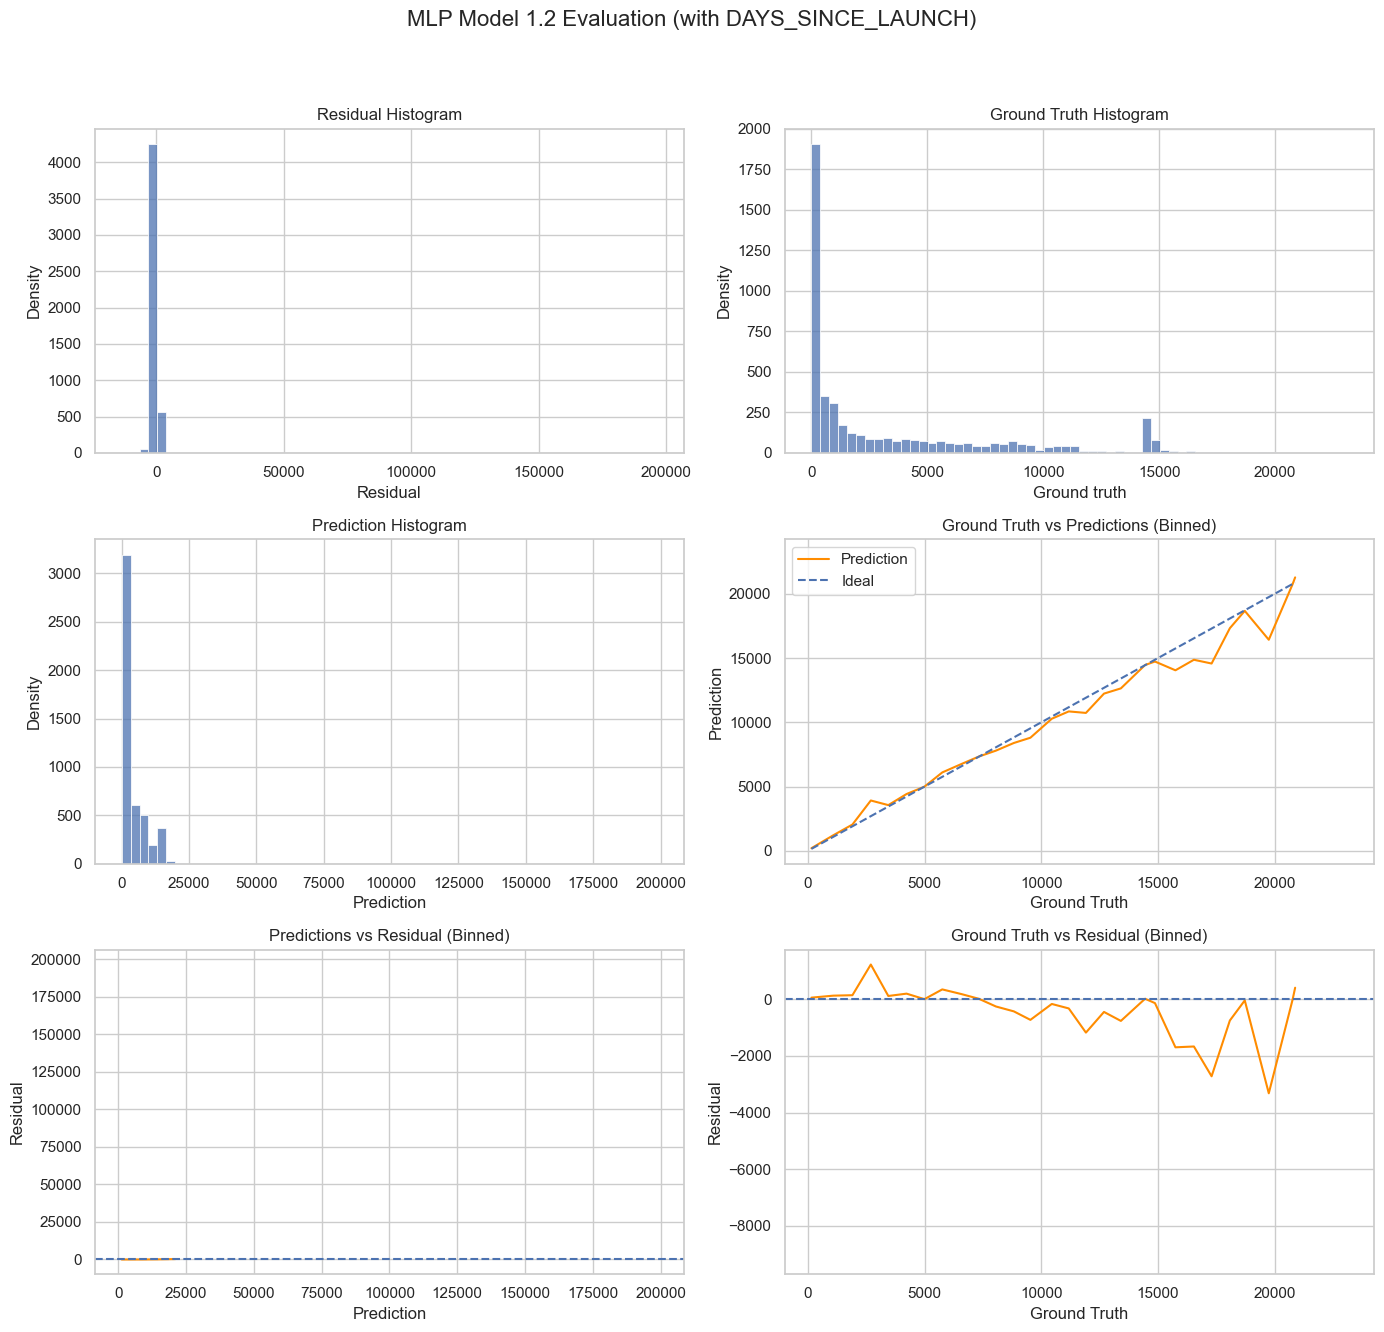

In [61]:
# plot model evaluation
y_pred1_2 = model1_2.predict(X_test1_2)
plot_model_evaluation(y_test1_2, y_pred1_2, title="MLP Model 1.2 Evaluation (with DAYS_SINCE_LAUNCH)")

In [62]:
# calculate feature importances
importances_1_2 = compute_permutation_importance(model1_2, X_test1_2, y_test1_2, model_name="Model 1.2")
importances_1_2.head(20)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 445us/step
Model 1.2 - Baseline RMSE: 3022.56
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 314us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 324us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 316us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 306us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 313us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 315us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 317us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 318us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 340us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 937us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 312us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 312us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 326us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 307us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 310us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 309us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 303us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 387us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 463us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 659us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 314us/step
153/153 ━━━━━━━━━━━

,Importance
EPOCH_YEAR,1651.898949
DAYS_SINCE_LAUNCH,1554.370280
MEAN_MOTION,1490.636539
LAUNCH_YEAR,1182.601117
ECCENTRICITY,101.289007
COUNTRY_CIS,36.136918
BSTAR,33.303518
PERIOD,27.210953
SEMIMAJOR_AXIS,24.275879
APOAPSIS,22.750145


In [63]:
# save model
model1_2.save("../Models/MLP1_2.keras")

### Model 1.3 - Using Remaining Lifetime as Label

In [64]:
# define features and labels for this model
X_train1_3 = train_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_train1_3 = train_df["REMAINING_LIFETIME"]

X_test1_3 = test_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_test1_3 = test_df["REMAINING_LIFETIME"]

In [65]:
# define model architecture
model1_3 = keras.Sequential([
    layers.Input(shape=(X_train1_3.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="relu")  # ensure output is non-negative
])

In [66]:
# compile model
model1_3.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[keras.metrics.RootMeanSquaredError()]
)

In [67]:
# train model
early_stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model1_3.fit(
    X_train1_3, y_train1_3,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 1s 852us/step - loss: 1558780.6250 - root_mean_squared_error: 1244.7073 - val_loss: 1162970.1250 - val_root_mean_squared_error: 1078.4109
Epoch 2/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 878us/step - loss: 1154117.8750 - root_mean_squared_error: 1072.1688 - val_loss: 1165173.5000 - val_root_mean_squared_error: 1079.4320
Epoch 3/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 752us/step - loss: 1014069.3750 - root_mean_squared_error: 1005.9963 - val_loss: 1175770.5000 - val_root_mean_squared_error: 1084.3295
Epoch 4/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 809us/step - loss: 1111151.7500 - root_mean_squared_error: 1052.7836 - val_loss: 1190297.2500 - val_root_mean_squared_error: 1091.0074
Epoch 5/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 865us/step - loss: 1037724.8125 - root_mean_squared_error: 1016.6389 - val_loss: 1193926.2500 - val_root_mean_squared_error: 1092.6693
Epoch 6/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1067479.3750 - root_mean_squared_error: 1029

In [68]:
# evaluate model
loss, rmse = model1_3.evaluate(X_test1_3, y_test1_3)
print("Test RMSE:", rmse)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 499us/step - loss: 762899.9375 - root_mean_squared_error: 870.8479
Test RMSE: 878.0259399414062


In [69]:
# evaluate different lifetime groups
y_pred1_3 = model1_3.predict(X_test1_3)

threshold = 4000
split_rsme1_3 = split_rmse_analysis(y_test1_3, y_pred1_3, threshold=threshold)
print(f"RSME for Remaining Lifetime ≤ {threshold} days: {split_rsme1_3['RMSE_low']}")
print(f"RSME for Remaining Lifetime > {threshold} days: {split_rsme1_3['RMSE_high']}")

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 428us/step
RSME for Remaining Lifetime ≤ 4000 days: 551.491698713589
RSME for Remaining Lifetime > 4000 days: 4118.073821582124


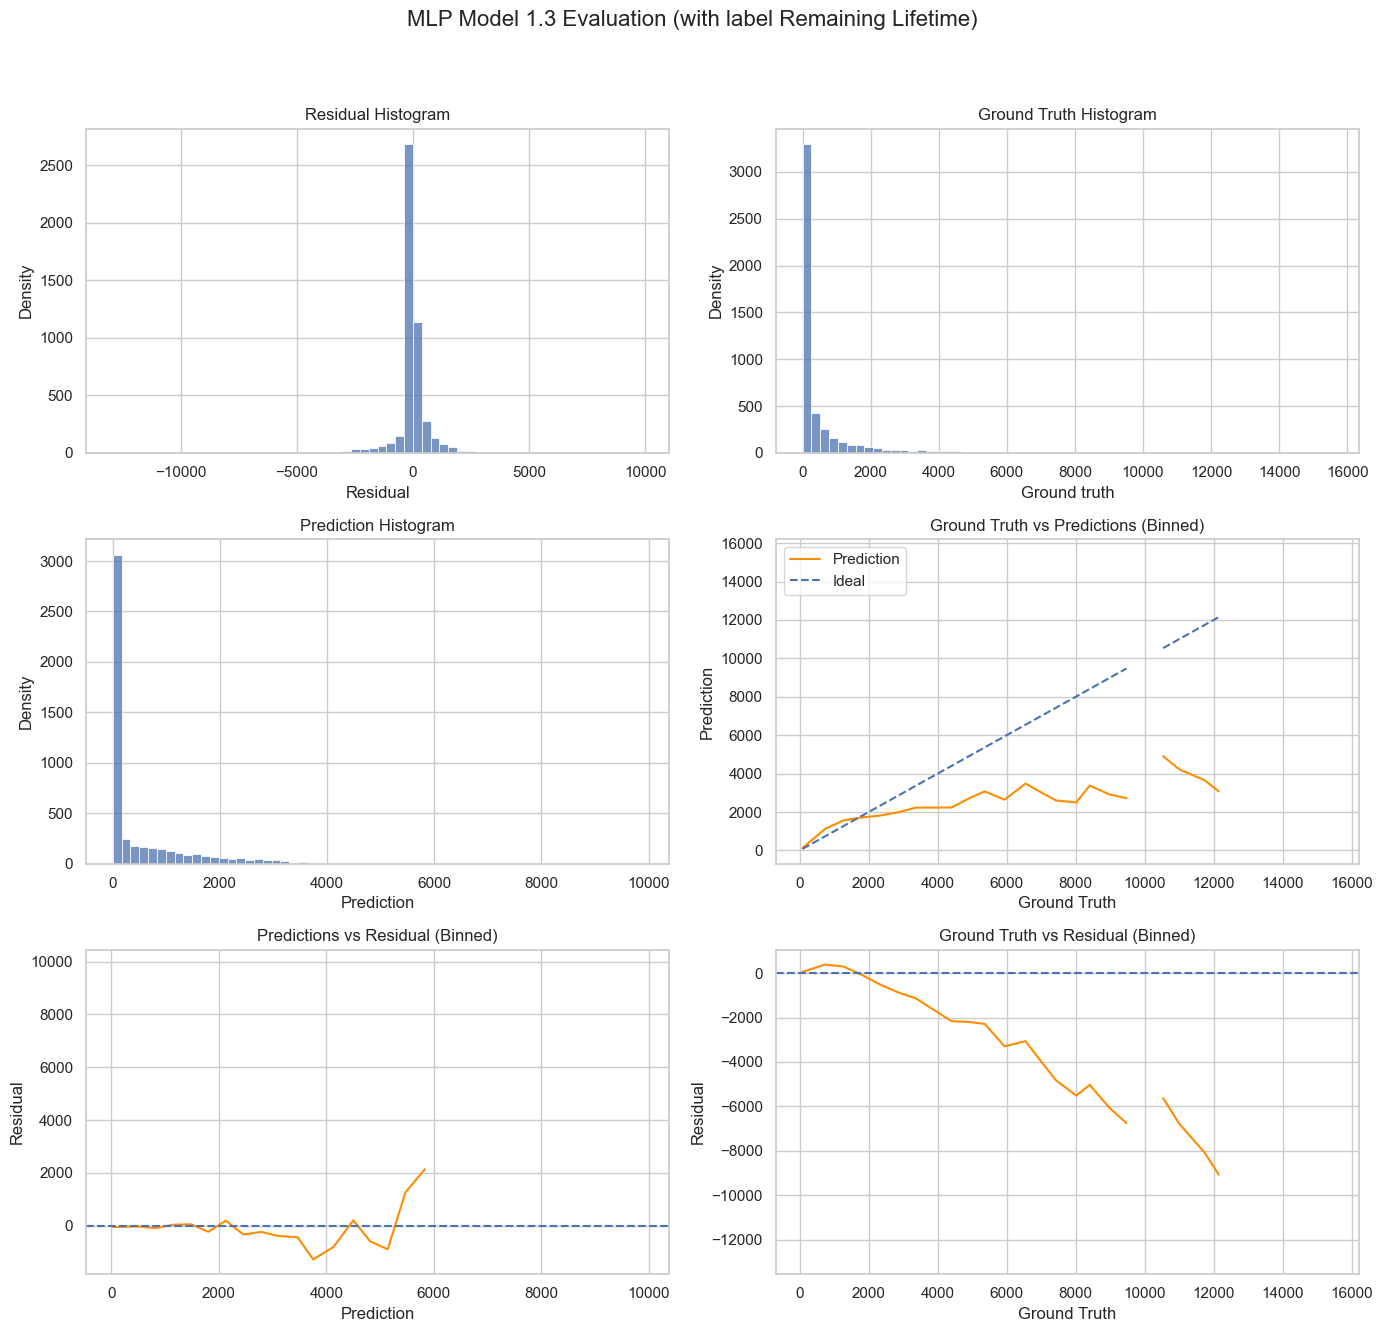

In [70]:
# plot model evaluation
plot_model_evaluation(y_test1_3, y_pred1_3, title="MLP Model 1.3 Evaluation (with label Remaining Lifetime)")

#### Predictions are really bad, so we will refine the architecture to adapt to the new label
All predictions are 0, the ReLU output neuron seems be "dead" — it never gets activated <br>
-> Change last layer from relu to linear activation function


In [71]:
# define model architecture (change last layer to linear activation)
model1_3 = keras.Sequential([
    layers.Input(shape=(X_train1_3.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="linear")  # change to linear 
])

In [72]:
# compile model
model1_3.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[keras.metrics.RootMeanSquaredError()]
)

In [73]:
# train model
early_stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model1_3.fit(
    X_train1_3, y_train1_3,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 1s 824us/step - loss: 1524208.1250 - root_mean_squared_error: 1233.1315 - val_loss: 1201524.7500 - val_root_mean_squared_error: 1096.1409
Epoch 2/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 716us/step - loss: 1127039.8750 - root_mean_squared_error: 1059.9872 - val_loss: 1202277.0000 - val_root_mean_squared_error: 1096.4839
Epoch 3/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 626us/step - loss: 1062560.1250 - root_mean_squared_error: 1029.9464 - val_loss: 1209115.0000 - val_root_mean_squared_error: 1099.5977
Epoch 4/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 620us/step - loss: 1113084.2500 - root_mean_squared_error: 1054.3168 - val_loss: 1194604.1250 - val_root_mean_squared_error: 1092.9795
Epoch 5/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 696us/step - loss: 1005193.3750 - root_mean_squared_error: 1002.1699 - val_loss: 1203046.6250 - val_root_mean_squared_error: 1096.8348
Epoch 6/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 616us/step - loss: 954810.5625 - root_mean_squared_error: 973

In [74]:
# evaluate model
loss, rmse = model1_3.evaluate(X_test1_3, y_test1_3)
print("Test RMSE:", rmse)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 797us/step - loss: 771277.3125 - root_mean_squared_error: 875.7769
Test RMSE: 886.776611328125


153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 402us/step


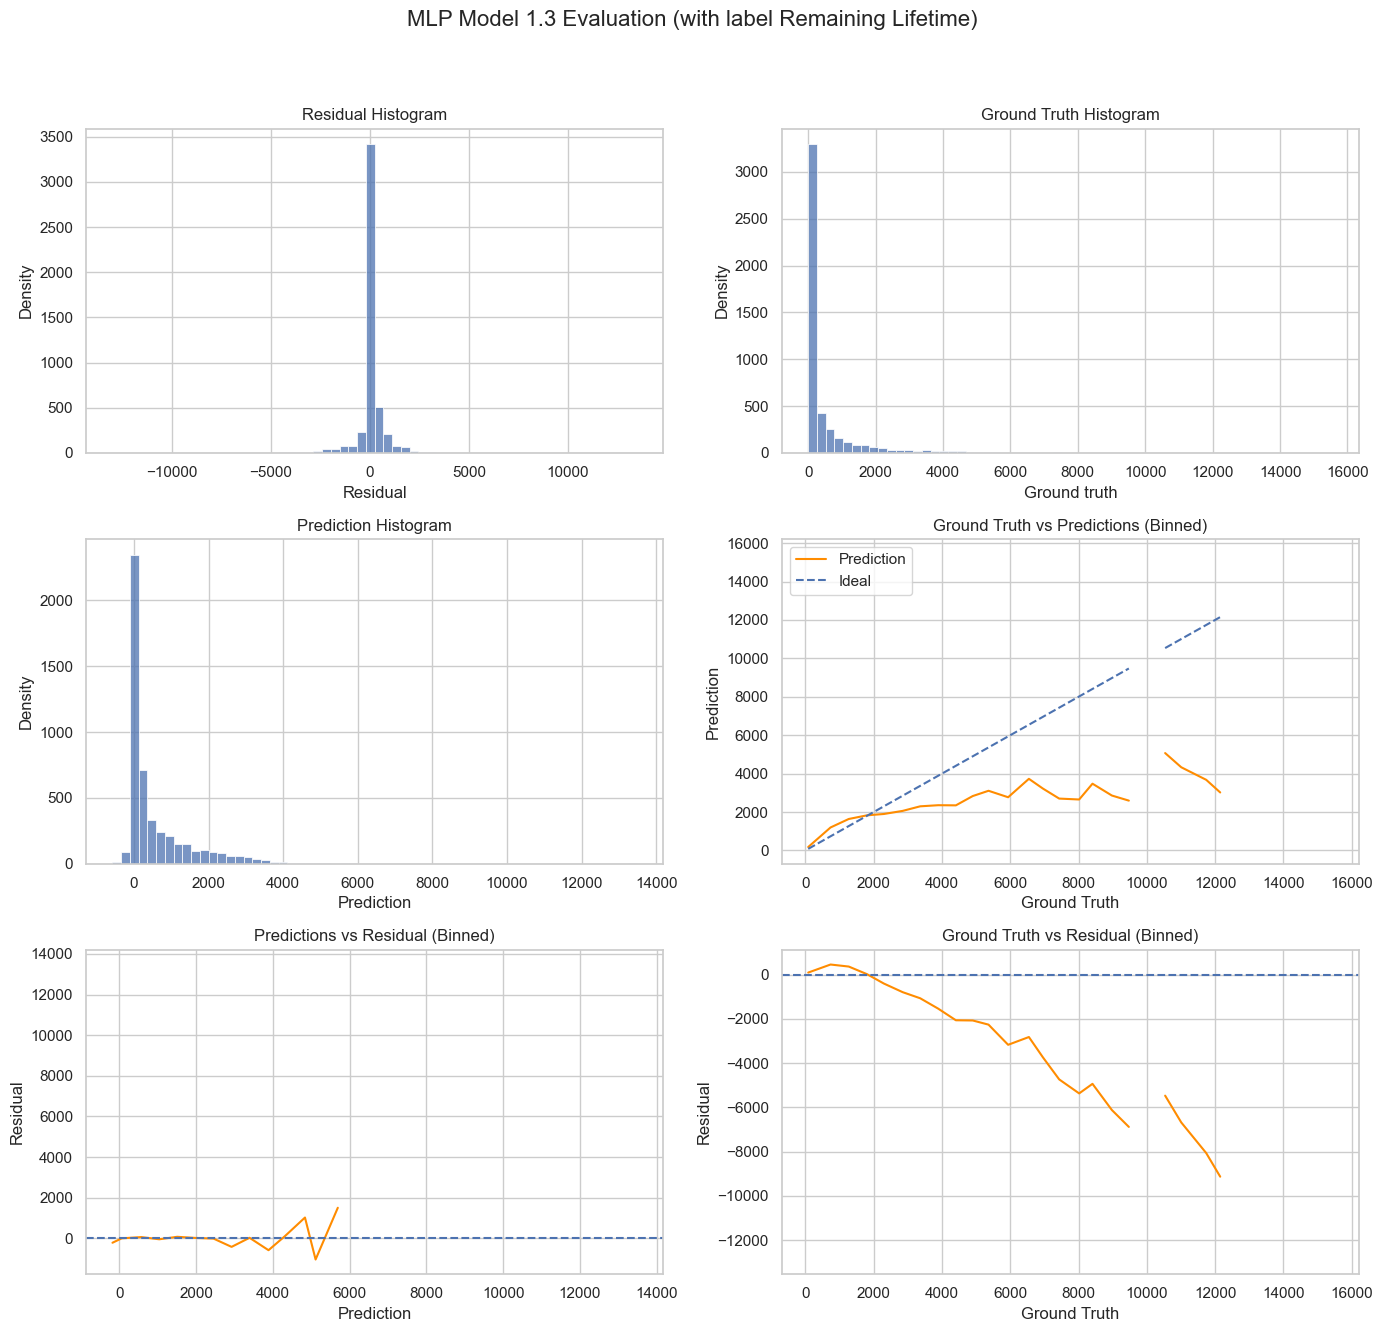

In [75]:
# plot model evaluation
y_pred1_3 = model1_3.predict(X_test1_3)
plot_model_evaluation(y_test1_3, y_pred1_3, title="MLP Model 1.3 Evaluation (with label Remaining Lifetime)")

In [76]:
# calculate feature importances
importances1_3 = compute_permutation_importance(model1_3, X_test1_3, y_test1_3, model_name="Model 1.3")
importances1_3.head(20)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 552us/step
Model 1.3 - Baseline RMSE: 886.78
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 308us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 301us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 297us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 299us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 321us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 305us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 299us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 301us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 302us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 302us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 300us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 301us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 303us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 302us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 337us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 336us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 316us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 537us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 318us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 317us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 319us/step
153/153 ━━━━━━━━━━━━

,Importance
MEAN_MOTION,549.833760
PERIAPSIS,173.313874
BSTAR,105.659145
DAYS_SINCE_LAUNCH,53.969233
EPOCH_YEAR,43.525220
OBJECT_TYPE_DEBRIS,42.479642
REV_AT_EPOCH,37.682554
OBJECT_TYPE_ROCKET BODY,26.588596
COUNTRY_US,26.413060
ECCENTRICITY,23.025600


In [77]:
# save model
model1_3.save("../Models/MLP1_3.keras")

### Model 1.4 - Using Lifetime again, but removing features related to epoch
Days since Launch, Revolutions at Epoch, Epoch Year & Epoch Month

In [78]:
# define features and labels fpr this model
X_train1_4 = train_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME", "DAYS_SINCE_LAUNCH", "REV_AT_EPOCH", "EPOCH_YEAR", "EPOCH_MONTH"])
y_train1_4 = train_df["LIFETIME"]

X_test1_4 = test_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME", "DAYS_SINCE_LAUNCH", "REV_AT_EPOCH", "EPOCH_YEAR", "EPOCH_MONTH"])
y_test1_4 = test_df["LIFETIME"]

In [79]:
# define model architecture
model1_4 = keras.Sequential([
    layers.Input(shape=(X_train1_4.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="relu")  # ensure output is non-negative
])

In [80]:
# compile model
model1_4.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[keras.metrics.RootMeanSquaredError()]
)

In [81]:
# train model
early_stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model1_4.fit(
    X_train1_4, y_train1_4,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 1s 754us/step - loss: 31797872.0000 - root_mean_squared_error: 5629.1802 - val_loss: 19249092.0000 - val_root_mean_squared_error: 4387.3789
Epoch 2/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 613us/step - loss: 15856320.0000 - root_mean_squared_error: 3981.3123 - val_loss: 18604096.0000 - val_root_mean_squared_error: 4313.2466
Epoch 3/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 652us/step - loss: 14591160.0000 - root_mean_squared_error: 3819.4663 - val_loss: 18149710.0000 - val_root_mean_squared_error: 4260.2476
Epoch 4/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 611us/step - loss: 14505674.0000 - root_mean_squared_error: 3807.1504 - val_loss: 17895258.0000 - val_root_mean_squared_error: 4230.2788
Epoch 5/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 617us/step - loss: 13985774.0000 - root_mean_squared_error: 3739.4905 - val_loss: 17579924.0000 - val_root_mean_squared_error: 4192.8418
Epoch 6/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 613us/step - loss: 13879405.0000 - root_mean_square

In [82]:
# evaluate model
loss, rmse = model1_4.evaluate(X_test1_4, y_test1_4)
print("Test RMSE:", rmse)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 425us/step - loss: 5174644.0000 - root_mean_squared_error: 2271.4487
Test RMSE: 2362.771240234375


153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 392us/step


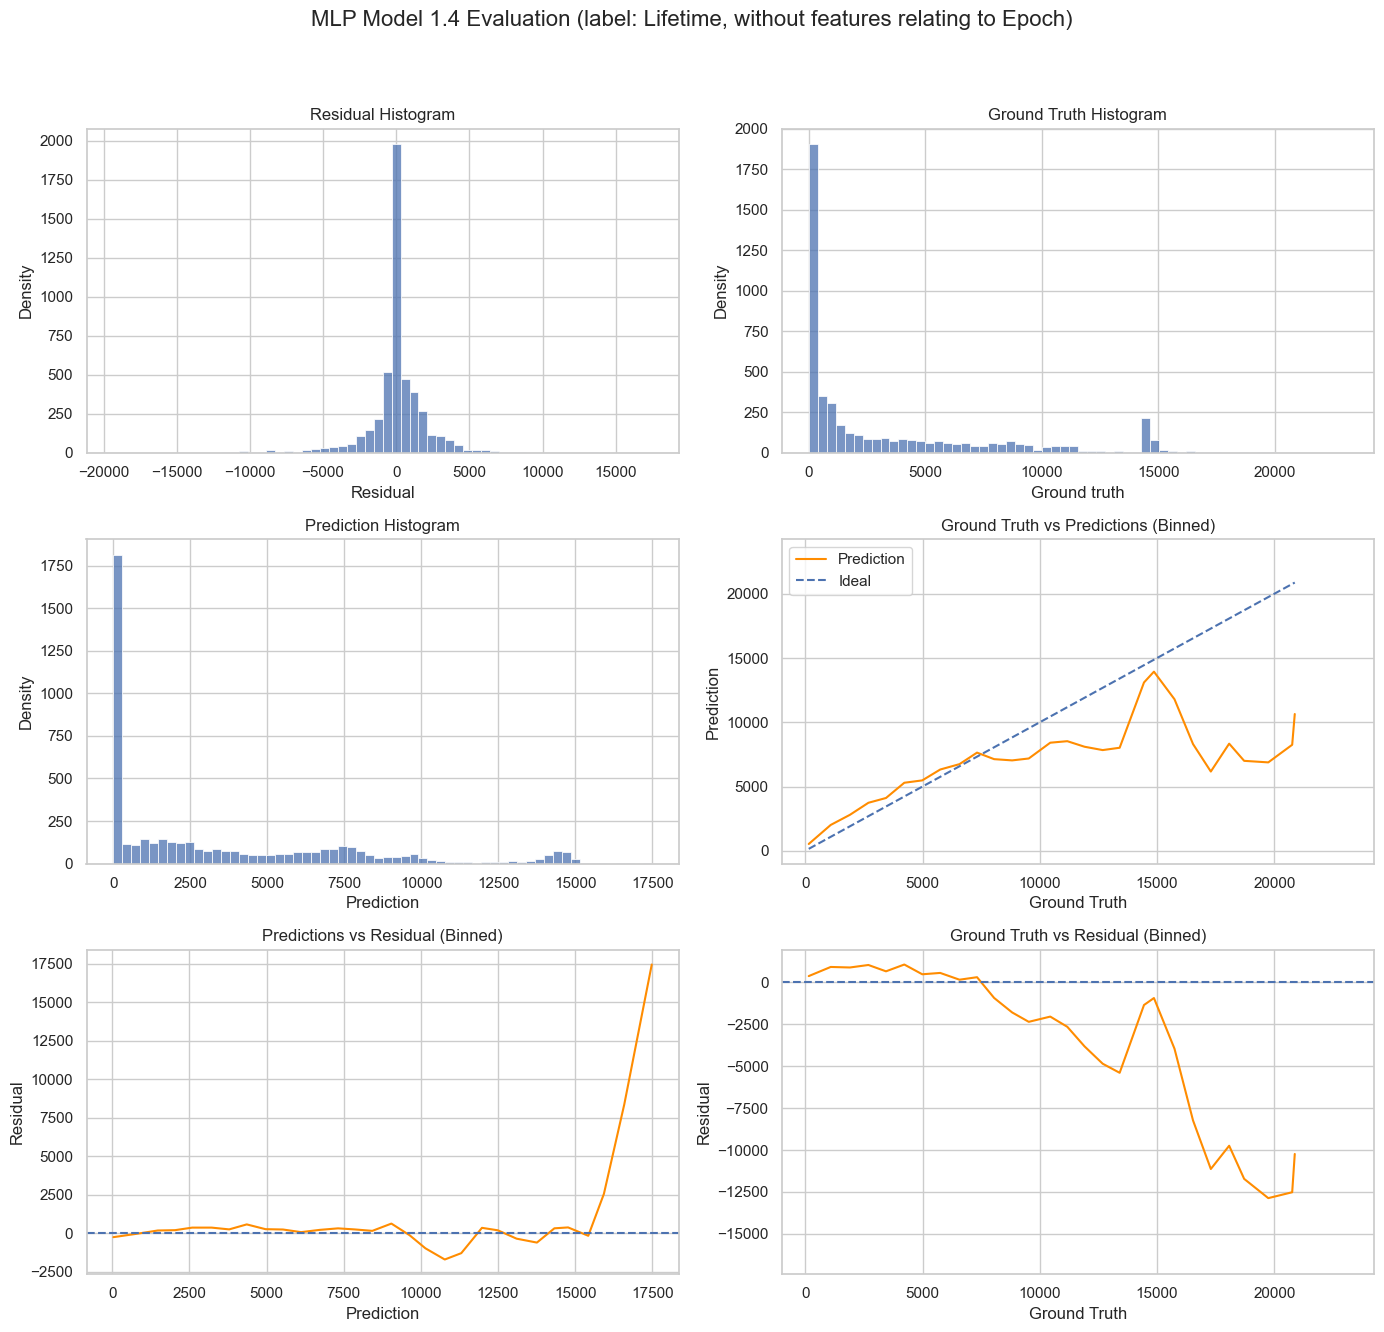

In [83]:
# plot model evaluation
y_pred1_4 = model1_4.predict(X_test1_4)
plot_model_evaluation(y_test1_4, y_pred1_4, title="MLP Model 1.4 Evaluation (label: Lifetime, without features relating to Epoch)")

In [84]:
# save model
model1_4.save("../Models/MLP1_4.keras")

## 2. Data Balancing
Continue using remaining Lifetime as label

### Model 2.1 - sample weights
Use inverse frequency based sample weights

In [85]:
# compute inverse frequency weights of years
train_sw_df = train_df.copy()
train_sw_df["REMAINING_LIFETIME_YEARS"] = (train_sw_df["REMAINING_LIFETIME"] / 365).round(0).astype(int)
year_freq = train_sw_df["REMAINING_LIFETIME_YEARS"].value_counts()
year_freq = year_freq / len(train_sw_df) # normalize to get frequency proportion

sample_weights = train_sw_df["REMAINING_LIFETIME_YEARS"].map(lambda y: 1 / year_freq[y]).values
sample_weights = np.log1p(sample_weights) # compress extremes
sample_weights = sample_weights / sample_weights.mean() # normalize

# drop column 
train_sw_df.drop(columns=['REMAINING_LIFETIME_YEARS'], inplace=True)

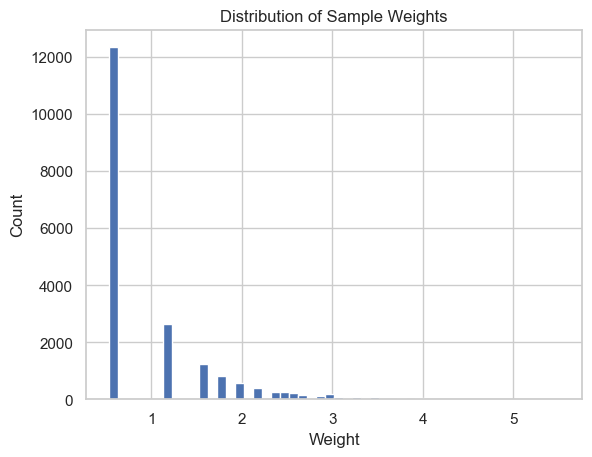

In [86]:
# visualize distribution of sample weights
import matplotlib.pyplot as plt
plt.hist(sample_weights, bins=50)
plt.title("Distribution of Sample Weights")
plt.xlabel("Weight")
plt.ylabel("Count")
plt.show()

In [87]:
# define features and labels for this model
X_train2_1 = train_sw_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_train2_1 = train_sw_df["REMAINING_LIFETIME"]

X_test2_1 = test_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_test2_1 = test_df["REMAINING_LIFETIME"]

In [88]:
# define model architecture 
model2_1 = keras.Sequential([
    layers.Input(shape=(X_train2_1.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="linear")  
])

In [89]:
# compile model
model2_1.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[keras.metrics.RootMeanSquaredError()]
)

In [90]:
# train model
early_stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model2_1.fit(
    X_train2_1, y_train2_1,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1, 
    sample_weight=sample_weights # specify sample weight array
)

Epoch 1/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 1s 781us/step - loss: 4836387.5000 - root_mean_squared_error: 1226.7633 - val_loss: 3399902.2500 - val_root_mean_squared_error: 1284.7175
Epoch 2/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 655us/step - loss: 2922150.7500 - root_mean_squared_error: 1154.9747 - val_loss: 3407685.7500 - val_root_mean_squared_error: 1316.8873
Epoch 3/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 631us/step - loss: 2864173.7500 - root_mean_squared_error: 1118.1627 - val_loss: 3451496.7500 - val_root_mean_squared_error: 1375.6656
Epoch 4/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 805us/step - loss: 2754849.0000 - root_mean_squared_error: 1109.6429 - val_loss: 3441490.2500 - val_root_mean_squared_error: 1362.5643
Epoch 5/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 640us/step - loss: 2824273.7500 - root_mean_squared_error: 1089.7625 - val_loss: 3449131.7500 - val_root_mean_squared_error: 1375.0698
Epoch 6/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 626us/step - loss: 2969718.0000 - root_mean_squared_error: 11

In [91]:
# evaluate model
loss, rmse = model2_1.evaluate(X_test2_1, y_test2_1)
print("Test RMSE:", rmse)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 450us/step - loss: 1519692.1250 - root_mean_squared_error: 1231.5497
Test RMSE: 1210.776611328125


153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 384us/step


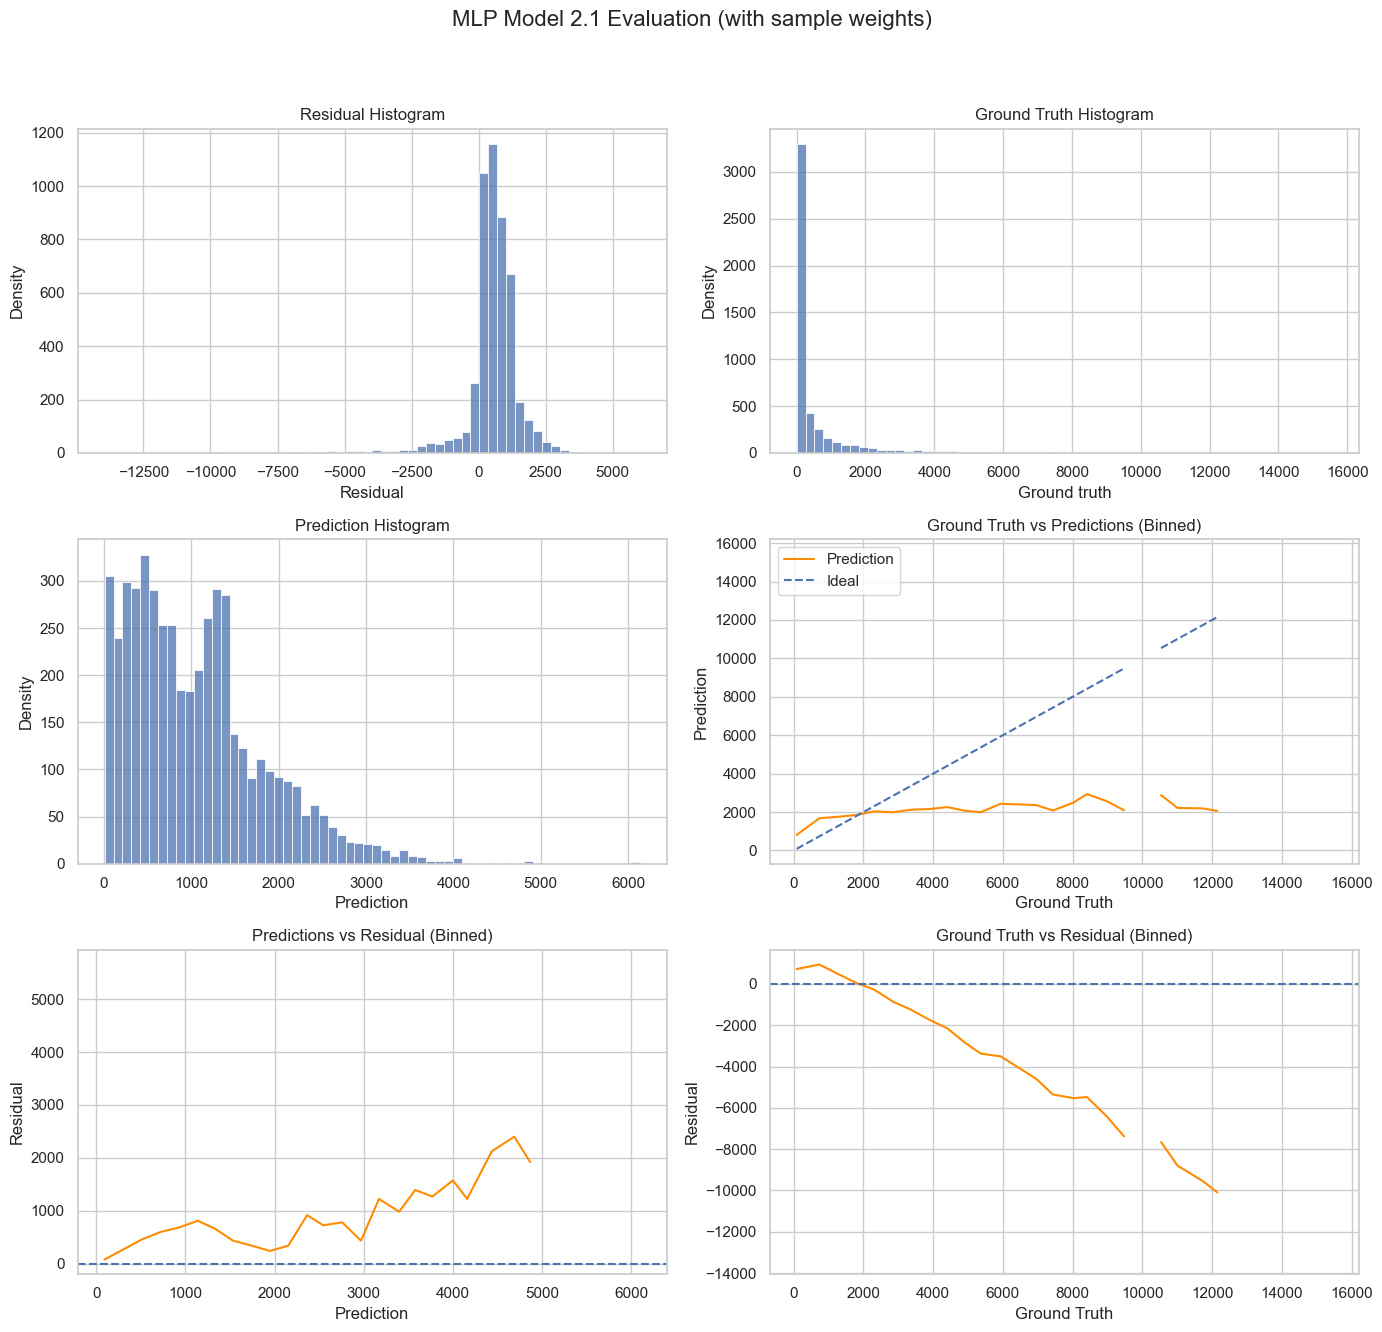

In [92]:
# plot model evaluation
y_pred2_1 = model2_1.predict(X_test2_1)
plot_model_evaluation(y_test2_1, y_pred2_1, title="MLP Model 2.1 Evaluation (with sample weights)")

#### Emphasize the weights on the tail more

In [93]:
# compute inverse frequency weights of years
train_sw_df = train_df.copy()
train_sw_df["REMAINING_LIFETIME_YEARS"] = (train_sw_df["REMAINING_LIFETIME"] / 365).round(0).astype(int)
year_freq = train_sw_df["REMAINING_LIFETIME_YEARS"].value_counts()
year_freq = year_freq / len(train_sw_df) # normalize to get frequency proportion

sample_weights = train_sw_df["REMAINING_LIFETIME_YEARS"].map(lambda y: 1 / year_freq[y] * 100).values
sample_weights = np.log1p(sample_weights) # compress extremes
sample_weights = sample_weights / sample_weights.mean() # normalize

# drop column 
train_sw_df.drop(columns=['REMAINING_LIFETIME_YEARS'], inplace=True)

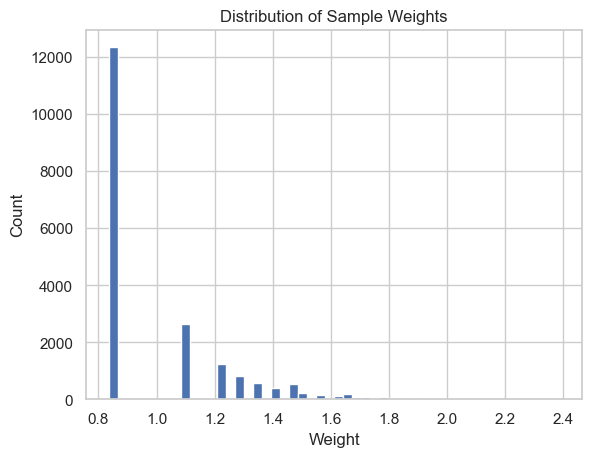

In [94]:
# visualize distribution of sample weights
import matplotlib.pyplot as plt
plt.hist(sample_weights, bins=50)
plt.title("Distribution of Sample Weights")
plt.xlabel("Weight")
plt.ylabel("Count")
plt.show()

In [95]:
# define features and labels for this model
X_train2_1 = train_sw_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_train2_1 = train_sw_df["REMAINING_LIFETIME"]

X_test2_1 = test_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_test2_1 = test_df["REMAINING_LIFETIME"]

In [96]:
# define model architecture 
model2_1 = keras.Sequential([
    layers.Input(shape=(X_train2_1.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="linear")  
])

In [97]:
# compile model
model2_1.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[keras.metrics.RootMeanSquaredError()]
)

In [98]:
# train model
early_stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model2_1.fit(
    X_train2_1, y_train2_1,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1, 
    sample_weight=sample_weights # specify sample weight array
)

Epoch 1/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 1s 895us/step - loss: 2723754.2500 - root_mean_squared_error: 1250.3772 - val_loss: 2039519.7500 - val_root_mean_squared_error: 1180.9689
Epoch 2/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 675us/step - loss: 1853665.5000 - root_mean_squared_error: 1084.7371 - val_loss: 2097890.5000 - val_root_mean_squared_error: 1214.0802
Epoch 3/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 641us/step - loss: 1854682.2500 - root_mean_squared_error: 1096.0082 - val_loss: 2135898.7500 - val_root_mean_squared_error: 1242.8304
Epoch 4/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 656us/step - loss: 1590762.0000 - root_mean_squared_error: 1003.5510 - val_loss: 2140629.7500 - val_root_mean_squared_error: 1247.9462
Epoch 5/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 773us/step - loss: 1715706.0000 - root_mean_squared_error: 1068.8574 - val_loss: 2146354.7500 - val_root_mean_squared_error: 1254.4728
Epoch 6/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 653us/step - loss: 1711576.3750 - root_mean_squared_error: 10

In [99]:
# evaluate model
loss, rmse = model2_1.evaluate(X_test2_1, y_test2_1)
print("Test RMSE:", rmse)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 449us/step - loss: 1246600.6250 - root_mean_squared_error: 1114.4296
Test RMSE: 1089.5885009765625


In [100]:
# evaluate different lifetime groups
y_pred2_1 = model2_1.predict(X_test2_1)

threshold = 4000
split_rsme2_1 = split_rmse_analysis(y_test2_1, y_pred2_1, threshold=threshold)
print(f"RSME for Remaining Lifetime ≤ {threshold} days: {split_rsme2_1['RMSE_low']}")
print(f"RSME for Remaining Lifetime > {threshold} days: {split_rsme2_1['RMSE_high']}")

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 376us/step
RSME for Remaining Lifetime ≤ 4000 days: 714.8344432454273
RSME for Remaining Lifetime > 4000 days: 4963.621661649889


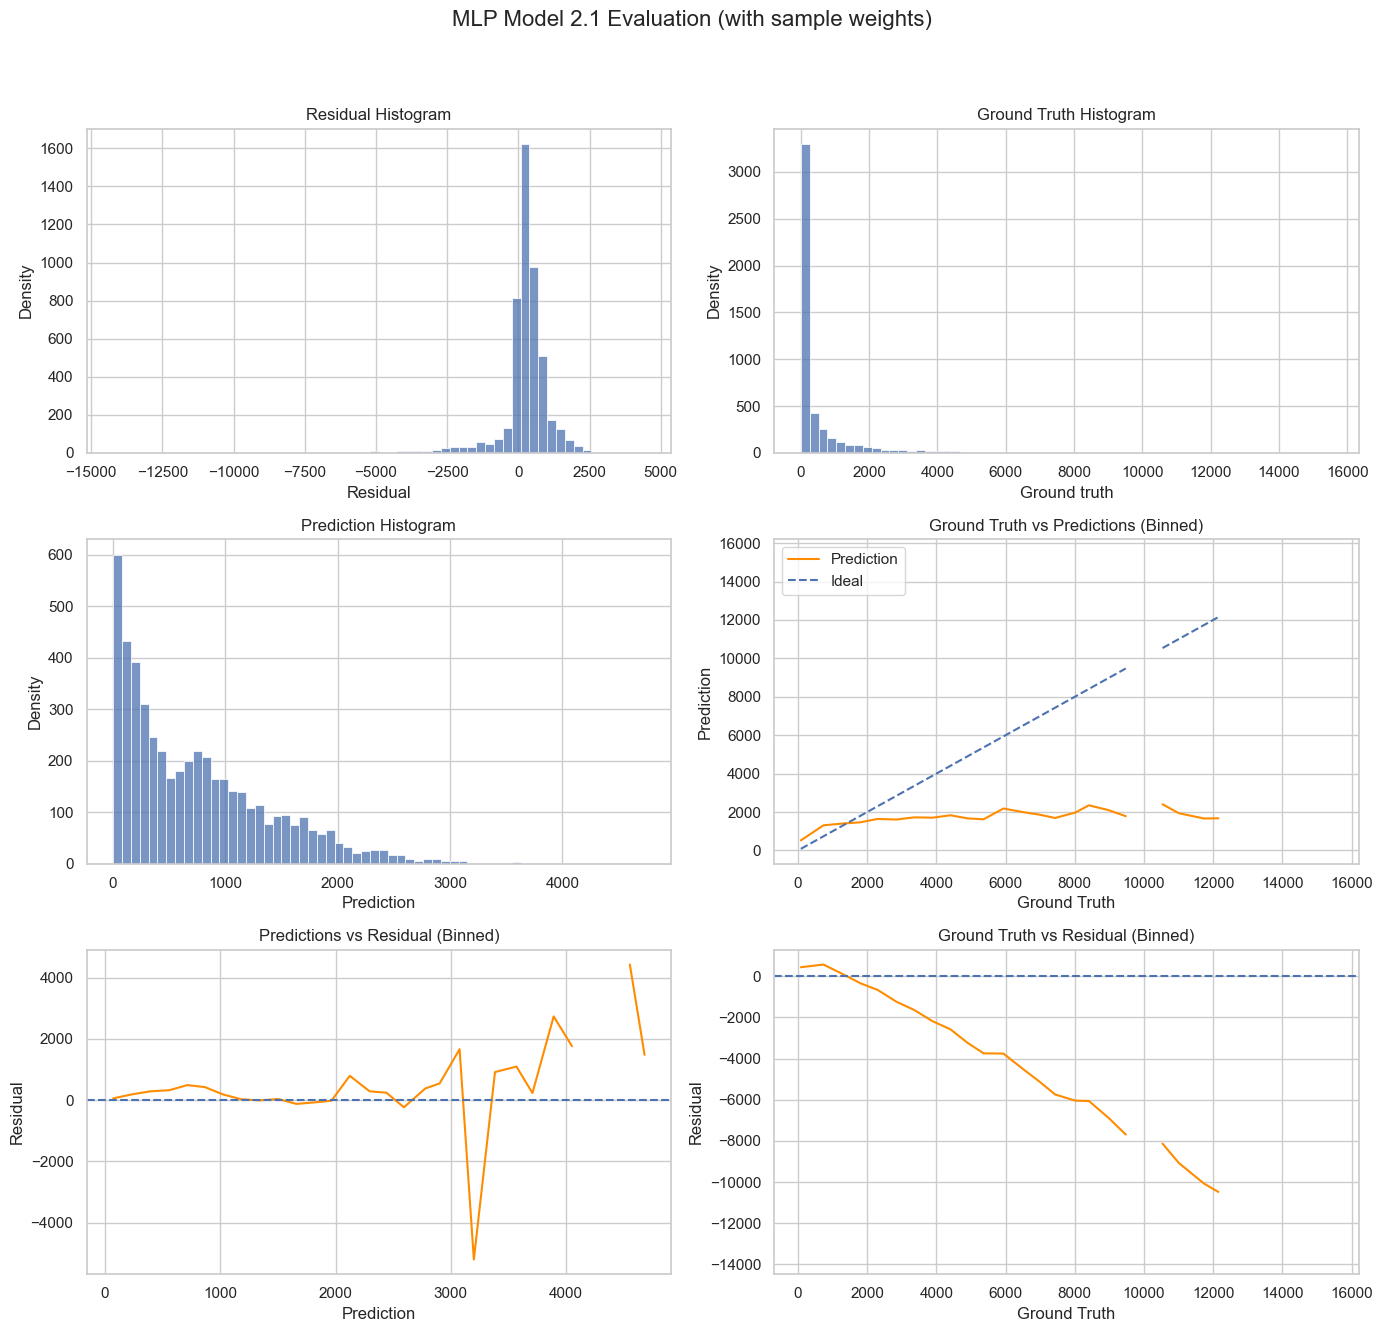

In [101]:
# plot model evaluation
plot_model_evaluation(y_test2_1, y_pred2_1, title="MLP Model 2.1 Evaluation (with sample weights)")

In [102]:
# save model
model2_1.save("../Models/MLP2_1.keras")

### Model 2.2 - SMOTE (smogn)

In [103]:
# load oversampled data with one hot encoding
train_smogn_df = pd.read_csv('../Data/TrainBalancedOHE.csv')
test_smogn_df = pd.read_csv('../Data/TestPreprocessed.csv') # original (not oversampled) test data, same as before

In [104]:
# define features and labels for this model
X_train2_2 = train_smogn_df.drop(columns=["REMAINING_LIFETIME"]) # Lifetime is not in dataset
y_train2_2 = train_smogn_df["REMAINING_LIFETIME"]

X_test2_2 = test_smogn_df.drop(columns=["NORAD_CAT_ID", "LIFETIME", "REMAINING_LIFETIME"])
y_test2_2 = test_smogn_df["REMAINING_LIFETIME"]

In [105]:
# define model architecture 
model2_2 = keras.Sequential([
    layers.Input(shape=(X_train2_2.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="linear")  
])

In [106]:
# compile model
model2_2.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[keras.metrics.RootMeanSquaredError()]
)

In [107]:
# train model
early_stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model2_2.fit(
    X_train2_2, y_train2_2,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1, 
)

Epoch 1/100
726/726 ━━━━━━━━━━━━━━━━━━━━ 1s 709us/step - loss: 4912087.0000 - root_mean_squared_error: 2202.7468 - val_loss: 1820379.5000 - val_root_mean_squared_error: 1349.2144
Epoch 2/100
726/726 ━━━━━━━━━━━━━━━━━━━━ 0s 603us/step - loss: 2641541.2500 - root_mean_squared_error: 1624.4991 - val_loss: 1864102.3750 - val_root_mean_squared_error: 1365.3213
Epoch 3/100
726/726 ━━━━━━━━━━━━━━━━━━━━ 0s 600us/step - loss: 2583442.0000 - root_mean_squared_error: 1607.0573 - val_loss: 1946229.1250 - val_root_mean_squared_error: 1395.0731
Epoch 4/100
726/726 ━━━━━━━━━━━━━━━━━━━━ 0s 607us/step - loss: 2755346.7500 - root_mean_squared_error: 1657.0756 - val_loss: 2047978.0000 - val_root_mean_squared_error: 1431.0758
Epoch 5/100
726/726 ━━━━━━━━━━━━━━━━━━━━ 1s 684us/step - loss: 2509597.5000 - root_mean_squared_error: 1583.7274 - val_loss: 2109744.0000 - val_root_mean_squared_error: 1452.4957
Epoch 6/100
726/726 ━━━━━━━━━━━━━━━━━━━━ 0s 601us/step - loss: 2447663.5000 - root_mean_squared_error: 15

In [108]:
# evaluate model
loss, rmse = model2_2.evaluate(X_test2_2, y_test2_2)
print("Test RMSE:", rmse)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 495us/step - loss: 1953062.7500 - root_mean_squared_error: 1322.9055
Test RMSE: 1676.5277099609375


In [109]:
# evaluate different lifetime groups
y_pred2_2 = model2_2.predict(X_test2_2)

threshold = 4000
split_rsme2_2 = split_rmse_analysis(y_test2_2, y_pred2_2, threshold=threshold)
print(f"RSME for Remaining Lifetime ≤ {threshold} days: {split_rsme2_2['RMSE_low']}")
print(f"RSME for Remaining Lifetime > {threshold} days: {split_rsme2_2['RMSE_high']}")

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 399us/step
RSME for Remaining Lifetime ≤ 4000 days: 1557.2571239201316
RSME for Remaining Lifetime > 4000 days: 4023.2090425430297


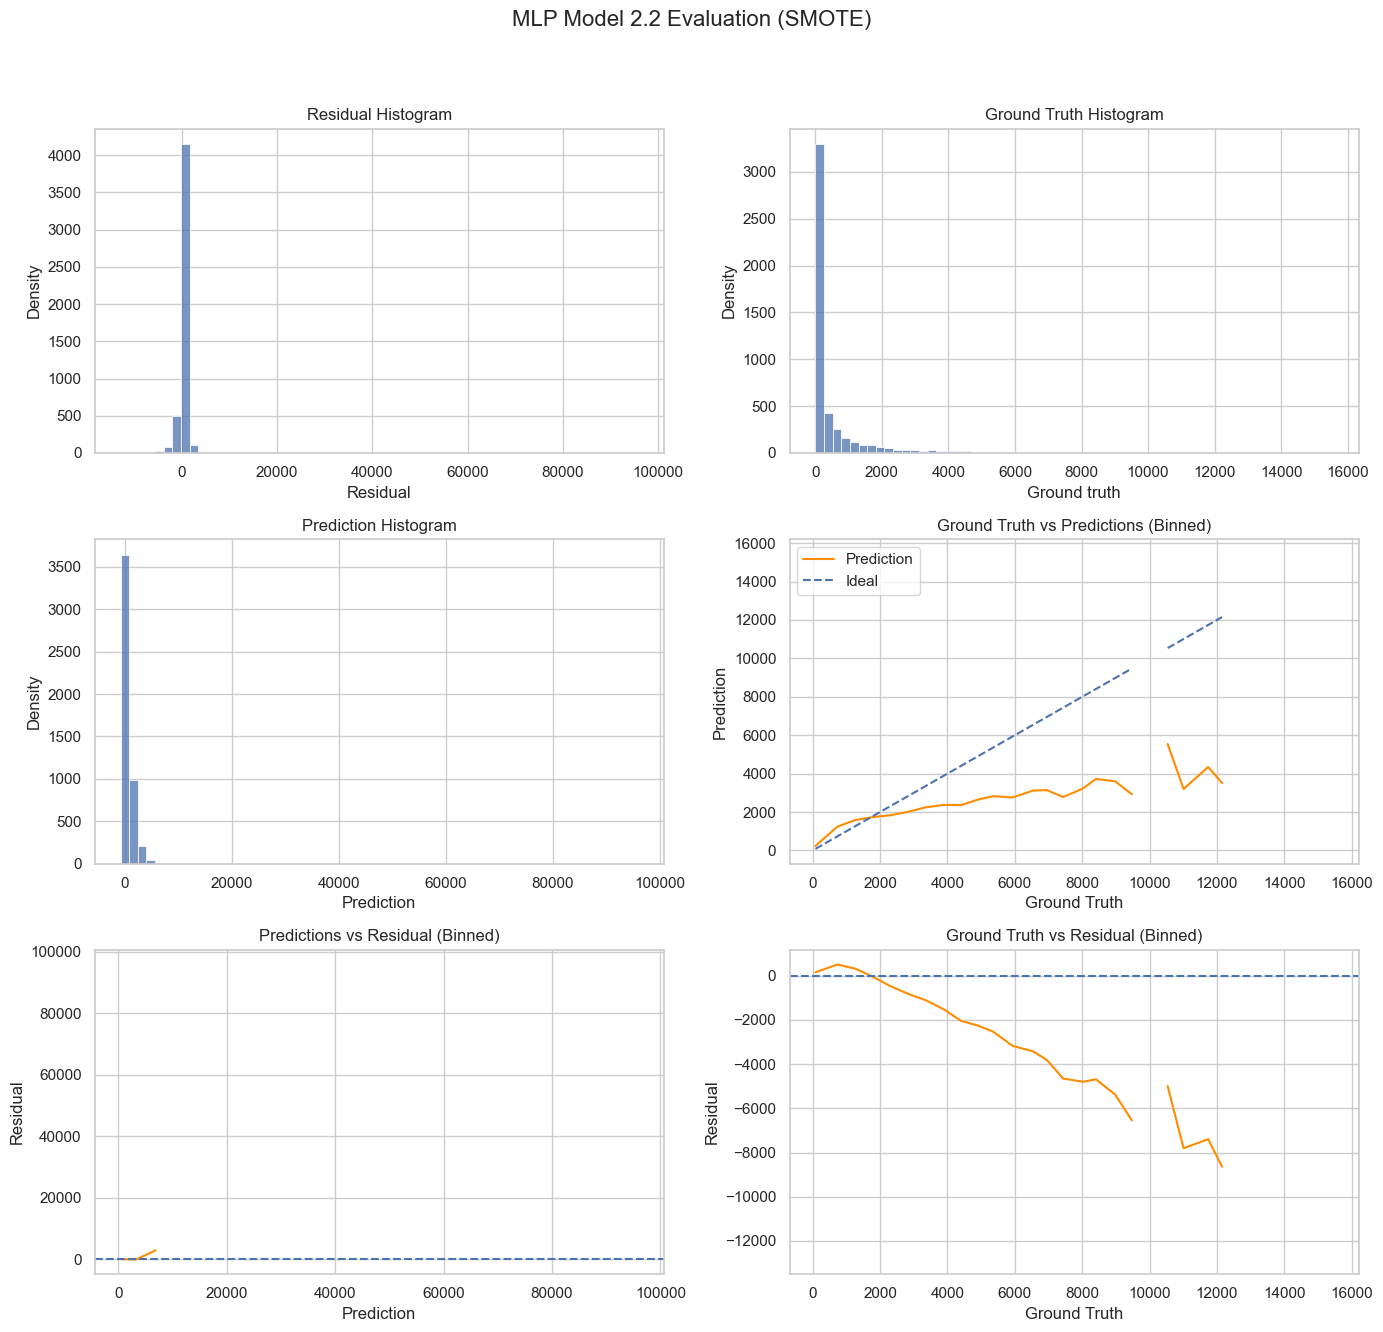

In [110]:
# plot model evaluation
plot_model_evaluation(y_test2_2, y_pred2_2, title="MLP Model 2.2 Evaluation (SMOTE)")

In [111]:
# save model
model2_2.save("../Models/MLP2_2.keras")